# **Лабораторна робота №6:** Марківські ланцюги, приховані марківські моделі


### Крічфалуши Дар'я, 2к. Маг., група МатШІ

**Мета роботи:** навчитися будувати та аналізувати скінченні однорідні марківські ланцюги, знаходити розподіли станів і стаціонарний розподіл, моделювати траєкторії у Python, розуміти структуру прихованої марківської моделі (HMM), вручну виконувати алгоритм Вітербі за таблицями  𝛿  та  𝜓 , а також перевіряти результат власною програмною реалізацією і бібліотекою ```hmmlearn```.

## Короткі теоретичні відомості

### 1. Марківський ланцюг

Послідовність випадкових станів $X_t$ називається ```марківським ланцюгом```, якщо майбутній стан залежить лише від поточного й не залежить від давнішої історії:

$$P(X_{t+1}=j \mid X_t=i,\,X_{t-1},\dots,X_0) = P(X_{t+1}=j \mid X_t=i)$$

Ланцюг **однорідний**, якщо ймовірності переходу не залежать від моменту часу $t$.

Тоді вони повністю описуються **матрицею переходів** $P = (p_{ij})$, де $p_{ij} = P(X_{t+1}=j \mid X_t=i)$, причому $p_{ij} \ge 0$ і $\sum_j p_{ij} = 1$.

Розподіл станів еволюціонує за правилом $\mu_1 = \mu_0 P$, а через $k$ кроків — $\mu_k = \mu_0 P^k$.

**Стаціонарний розподіл** $\pi$ задовольняє $\pi P = \pi$ і $\sum_i \pi_i = 1$. Для регулярного ланцюга $\mu_k \to \pi$ незалежно від початкового розподілу.



### 2. Прихована марківська модель

У звичайному ланцюзі стан $X_t$ спостерігається безпосередньо. У HMM стан $Z_t$ **прихований**, а ми бачимо лише спостереження $O_t$, яке залежить від поточного прихованого стану. Модель задається трійкою $(\pi, A, B)$:

* $\pi$ - початковий розподіл прихованих станів;
* $A = (a_{ij})$, $a_{ij} = P(Z_t = j \mid Z_{t-1} = i)$ — матриця переходів;
* $B$, $b_j(o_t) = P(O_t = o_t \mid Z_t = j)$ - імовірності емісій.

Отже, HMM - це подвійний стохастичний процес: прихований ланцюг породжує стани, а кожен стан стохастично породжує спостереження.


### 3. Задача декодування та алгоритм Вітербі

За відомими $(\pi, A, B)$ і послідовністю спостережень $O = (o_1,\dots,o_T)$ знайти найімовірнішу послідовність прихованих станів $Z^* = \arg\max_Z P(Z \mid O)$.

Повний перебір потребував би $N^T$ операцій. **Алгоритм Вітербі** використовує динамічне програмування і зберігає для кожного моменту й кожного стану лише найкращий частковий шлях, що дає складність $O(TN^2)$:

$$\delta_t(j) = \max_{z_1 \dots z_{t-1}} P(z_1,\dots,z_{t-1},\,Z_t = j,\,o_1,\dots,o_t)$$
$$\psi_t(j) = \arg\max_i \bigl[\delta_{t-1}(i)\,a_{ij}\bigr]$$

Ініціалізація: $\delta_1(j) = \pi_j b_j(o_1)$.

Рекурсія: $\delta_t(j) = \bigl[\max_i \delta_{t-1}(i)a_{ij}\bigr]b_j(o_t)$.

Завершення: $z_T^* = \arg\max_j \delta_T(j)$. Зворотний хід: $z_{t-1}^* = \psi_t(z_t^*)$.



---



## Постановка задачі

Умовна модель режимів фондового ринку.

### Приховані стани

| Позначення | Зміст |
|---|---|
| $G$ | режим **зростання** економіки |
| $R$ | режим **спаду** економіки |

Стан економіки безпосередньо не спостерігається - він є латентною характеристикою, яку не можна виміряти одним числом.

### Спостереження

| Позначення | Зміст |
|---|---|
| $+$ | позитивна щоденна дохідність індексу |
| $-$ | негативна щоденна дохідність індексу |

Спостерігається лише **знак** щоденної дохідності - це єдина доступна інформація про прихований режим.

### Параметри моделі

**Початковий розподіл прихованого стану:**
$$\pi = \begin{pmatrix} 0.6 & 0.4 \end{pmatrix}$$
тобто спочатку економіка перебуває в режимі зростання з імовірністю 0.6 і в режимі спаду з імовірністю 0.4.

**Матриця переходів між режимами:**
$$A = \begin{pmatrix} 0.8 & 0.2 \\ 0.3 & 0.7 \end{pmatrix}$$
Рядки відповідають **поточному** стану, стовпці - **наступному**.

**Матриця емісій:**
$$B = \begin{pmatrix} 0.75 & 0.25 \\ 0.20 & 0.80 \end{pmatrix}$$
Перший стовпець відповідає спостереженню $+$, другий - спостереженню $-$.

**Послідовність спостережень:** $O = (+,\,-,\,+)$.


Ініціалізація параметрів

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.set_printoptions(precision=6, suppress=True)
pd.set_option("display.float_format", lambda v: f"{v:.6f}")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10,
                     "figure.facecolor": "white"})

hidden_states = ["Зростання", "Спад"]   # G, R
observations_sym = ["+", "-"]

pi = np.array([0.6, 0.4])
A = np.array([[0.8, 0.2],
              [0.3, 0.7]])
B = np.array([[0.75, 0.25],      # рядок G: P(+|G), P(-|G)
              [0.20, 0.80]])     # рядок R: P(+|R), P(-|R)

observations = ["+", "-", "+"]
obs_to_int = {"+": 0, "-": 1}
obs_idx = [obs_to_int[o] for o in observations]

print("π =", pi)
print("A =\n", A)
print("B =\n", B)
print("O =", observations, "-> індекси", obs_idx)


π = [0.6 0.4]
A =
 [[0.8 0.2]
 [0.3 0.7]]
B =
 [[0.75 0.25]
 [0.2  0.8 ]]
O = ['+', '-', '+'] -> індекси [0, 1, 0]


## **Завдання 1.** Перевірка матриці переходів

### 1.1. Суми елементів кожного рядка

$$
G:\quad 0.8+0.2=1.0\\
R:\quad 0.3+0.7=1.0
$$


### 1.2. Чому суми мають дорівнювати одиниці

Кожен рядок матриці А - це **умовний ймовірнісний розподіл** наступного стану за умови, що поточний стан відомий:
$$
\sum_ja_{ij}=\sum_jP(Z_{t+1}=j \ | \ Z_t=i)=P(Ω \ | \ Z_t=i)=1
$$

**Події** $A=$"наступний стан $= G$" і $B=$"наступний стан $= R$" **несумісні** $⟹A\cap B=\varnothing$. А також "вичерпні", тобто система обов'язково опиниться в якомусь із двох станів. За аксіомою нормування повна група несумісних подій має сумарну ймовірність 1.

Матриця з такою властивістю називається **стохастичною за рядками** (row-stochastic).

Якщо сума рядка менша за 1, частина ймовірнісної маси "губиться"; якщо більша - модель приписує подіям сумарну ймовірність понад 100%.

І те, й інше робить обчислення $\mu_k = \mu_0 A^k$ беззмістовними.





### 1.3. Інтерпретація чисел словами

$a_{GG}=0.8:\quad P(Z_{t+1}=G \ | \ Z_t=G)$
* якщо економіка зростає, то з ймовірністю $80\%$ наступного періоду вона продовжить зростати.

$a_{GR}=0.2:\quad P(Z_{t+1}=R \ | \ Z_t=G)$
* якщо економіка зростає, то з ймовірністю $20\%$ вона перейде у спад.

$a_{RG}=0.3:\quad P(Z_{t+1}=G \ | \ Z_t=R)$
* якщо економіка у спаді, то з ймовірністю $30\%$ вона відновиться до зростання.

$a_{RR}=0.7:\quad P(Z_{t+1}=R \ | \ Z_t=R)$
* якщо економіка у спаді, то з ймовірністю $70\%$ спад триватиме.


**Економічний зміст.** обидви діагональні елементи великі $0.8,0.7$, тобто ланцюг **інерційний**: режим схильні зберігатися, а не змінюватися щороку. Це відповідає реальності - економічні цикли тривають місяцями й роками, а не перемикатися щодня.

Зростання стійкіше за спад, а ймовірність виходу зі спаду вища за ймовірність входу в нього $(0.3>0.2)$, тому в довгостроковому режимі зростання має переважати.

Очікувана тривалість перебування в режимі - це середнє геометричне розподілу з параметром виходу:

$$
E[\text{тривалість } G] = \frac{1}{1-a_{GG}} = \frac{1}{0.2} = 5 \text{ періодів}, \qquad E[\text{тривалість } R] = \frac{1}{1-a_{RR}} = \frac{1}{0.3} \approx 3.33 \text{ періоди}
$$


In [3]:
print("Матриця переходів A:")
print(A)

row_sums = A.sum(axis=1)
print("\nСуми рядків:", row_sums)

assert np.allclose(row_sums, 1.0), "Помилка: не всі рядки сумуються до 1."
print("Перевірка пройдена.")

# для порівняння - суми стовпців (НЕ мають сенсу для стохастичної матриці)
print("\nСуми стовпців (не зобов'язані дорівнювати 1):", A.sum(axis=0))

print("\nОчікувана тривалість режимів:")
for i, s in enumerate(hidden_states):
    print(f"  {s}: 1/(1-a_{{{i}{i}}}) = 1/{1-A[i,i]:.1f} = {1/(1-A[i,i]):.4f} періодів")


Матриця переходів A:
[[0.8 0.2]
 [0.3 0.7]]

Суми рядків: [1. 1.]
Перевірка пройдена.

Суми стовпців (не зобов'язані дорівнювати 1): [1.1 0.9]

Очікувана тривалість режимів:
  Зростання: 1/(1-a_{00}) = 1/0.2 = 5.0000 періодів
  Спад: 1/(1-a_{11}) = 1/0.3 = 3.3333 періодів


## **Завдання 2.** Розподіли станів і матриця $A^k$

### 2.1. Ручний розрахунок $\mu_1=\mu_0A$

Нехай початковий розподіл режимів $\mu_0=\left(0.6 \quad 0.4\right)$.

Множення рядка на матрицю:
$$
\mu_1=\begin{pmatrix} 0.6 & 0.4 \end{pmatrix}\begin{pmatrix} 0.8 & 0.2 \\ 0.3 & 0.7 \end{pmatrix}
$$

1. **Перша компонента** - ймовірність режиму зростання:
$$
P(Z_1=G)=0.6\cdot0.8+0.4\cdot0.3=0.48+0.12=0.60
$$

Потрапити у зростання можна двома несумісними шляхами - бути у зростанні й залишитися $(0.6\cdot0.8)$ або бути у спаді й відновитися $(0.4\cdot0.3)$. Це формула **повної ймовірності**.

2. **Друга компонетна** - ймовірність режиму спаду:
$$
P(Z_1=R)=0.6\cdot0.2+0.4\cdot0.7=0.12+0.28=0.40
$$

3. **Перевірка:**
$$
0.60+0.40=1.00 \\
\mu_1=(0.6\quad0.4)
$$

Виконується.

### 2.2. Важливе спостереження

$$
\mu_1=\mu_0
$$

Розподіл не змінився. А все через те, що заданий в умові початковий розпділ уже **є стаціонарним** розподілом цього ланцюга. Отже:
$$
\mu_k=\mu_0A^k=(0.6\quad0.4)\quad ∀k=0,1,2,\dots
$$

Графік динаміки розподілу буде складатися з двох горизонтальних прямих.

Щоб проілюструвати збіжність до стаціонарного розподілу (про яку йдеться в теоретичній частині), нижчк додатково обчислено еволюцію з двох інших початкових розподілів: $(1,0)$ - точно зростання, $(0,1)$ - точно спад.

In [4]:
mu0 = np.array([0.6, 0.4])

distributions = [mu0]
for k in range(1, 21):
    mu_next = distributions[-1] @ A
    distributions.append(mu_next)

df_dist = pd.DataFrame(distributions, columns=["Зростання", "Спад"])
df_dist.index.name = "Період"
print("Динаміка розподілу з μ0 = (0.6, 0.4):\n")
print(df_dist.head(6).round(6).to_string())
print("...")
print(df_dist.tail(2).round(6).to_string())

print(f"\nμ1 обчислено кодом: {distributions[1]}")
print(f"μ1 обчислено вручну: [0.6 0.4]   -> збігається")
print(f"сума компонент μ1 = {distributions[1].sum():.10f}")


Динаміка розподілу з μ0 = (0.6, 0.4):

        Зростання     Спад
Період                    
0        0.600000 0.400000
1        0.600000 0.400000
2        0.600000 0.400000
3        0.600000 0.400000
4        0.600000 0.400000
5        0.600000 0.400000
...
        Зростання     Спад
Період                    
19       0.600000 0.400000
20       0.600000 0.400000

μ1 обчислено кодом: [0.6 0.4]
μ1 обчислено вручну: [0.6 0.4]   -> збігається
сума компонент μ1 = 1.0000000000


#### Порівняння циклічного обчислення з матричним піднесенням до степеня

In [5]:
k = 10
mu10_by_power = mu0 @ np.linalg.matrix_power(A, k)
print("mu_10 через A^10:", mu10_by_power)
print("mu_10 з таблиці :", distributions[k])
print("різниця         :", np.abs(mu10_by_power - distributions[k]))
print("\nA^10 =\n", np.linalg.matrix_power(A, k))
print("\nОбидва способи дають однаковий результат, бо μ_k = μ_0·A^k -")
print("це те саме, що застосувати A рівно k разів поспіль (асоціативність множення).")
print("Різниця лише в обчислювальній вартості: цикл дає всі проміжні розподіли,")
print("а matrix_power через бінарне піднесення коштує O(log k) множень матриць.")


mu_10 через A^10: [0.6 0.4]
mu_10 з таблиці : [0.6 0.4]
різниця         : [0. 0.]

A^10 =
 [[0.600391 0.399609]
 [0.599414 0.400586]]

Обидва способи дають однаковий результат, бо μ_k = μ_0·A^k -
це те саме, що застосувати A рівно k разів поспіль (асоціативність множення).
Різниця лише в обчислювальній вартості: цикл дає всі проміжні розподіли,
а matrix_power через бінарне піднесення коштує O(log k) множень матриць.


#### Графік з $\mu_0=(0.6\quad0.4)$ та з двох інших розподілів

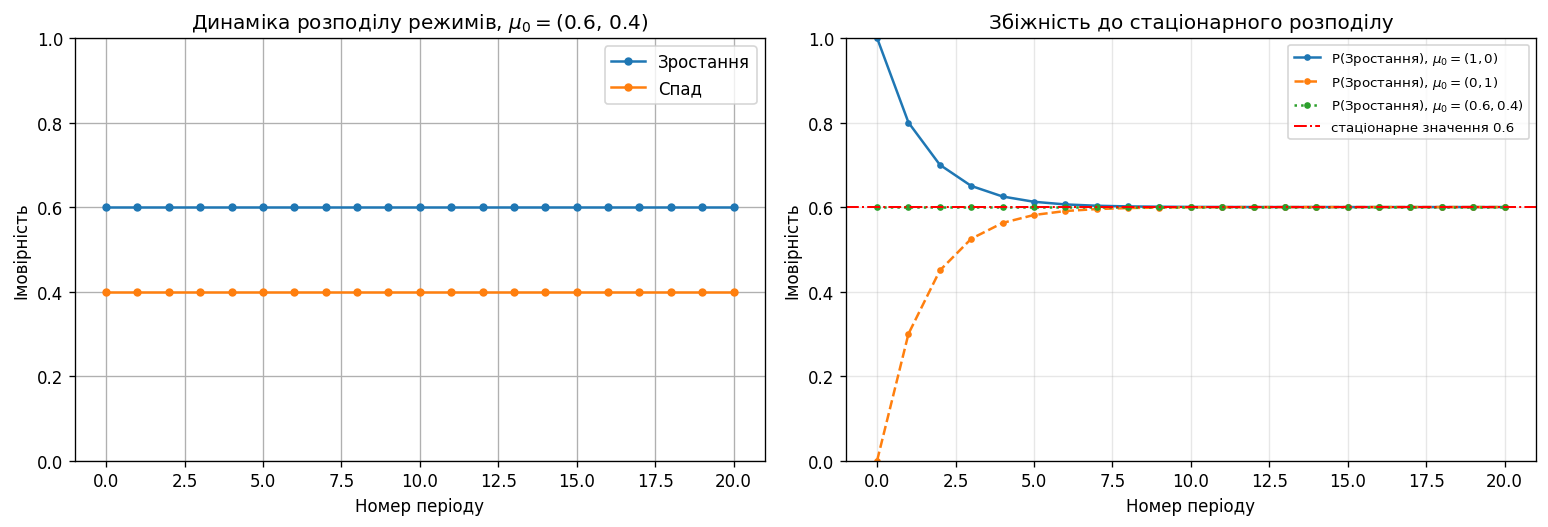

Ліворуч: розподіл не змінюється, бо μ0 вже стаціонарний.
Праворуч: з будь-якого іншого старту розподіл збігається до (0.6, 0.4)
          — це ілюстрація регулярності ланцюга.


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

df_dist.plot(ax=ax[0], marker="o", ms=4, grid=True)
ax[0].set_xlabel("Номер періоду"); ax[0].set_ylabel("Імовірність")
ax[0].set_title("Динаміка розподілу режимів, $\\mu_0=(0.6,\\,0.4)$")
ax[0].set_ylim(0, 1)

for m0, style, lbl in [(np.array([1.0, 0.0]), '-', '$\\mu_0=(1,0)$'),
                       (np.array([0.0, 1.0]), '--', '$\\mu_0=(0,1)$'),
                       (mu0, ':', '$\\mu_0=(0.6,0.4)$')]:
    traj = [m0]
    for _ in range(20):
        traj.append(traj[-1] @ A)
    ax[1].plot([v[0] for v in traj], style, marker='o', ms=3,
               label=f'P(Зростання), {lbl}')
ax[1].axhline(0.6, c='red', lw=1.2, ls='-.', label='стаціонарне значення 0.6')
ax[1].set_xlabel("Номер періоду"); ax[1].set_ylabel("Імовірність")
ax[1].set_title("Збіжність до стаціонарного розподілу")
ax[1].set_ylim(0, 1); ax[1].grid(True, alpha=0.3); ax[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

print("Ліворуч: розподіл не змінюється, бо μ0 вже стаціонарний.")
print("Праворуч: з будь-якого іншого старту розподіл збігається до (0.6, 0.4)")
print("          — це ілюстрація регулярності ланцюга.")


## **Завдання 3.** Стаціонарний розподіл

### 3.1. Ручний розв'язок

Нехай стаціонарний розподіл $\pi^*=(x\quad y)$. Складаємо систему:
$$
\begin{pmatrix} x & y \end{pmatrix}\begin{pmatrix} 0.8 & 0.2 \\ 0.3 & 0.7 \end{pmatrix} = \begin{pmatrix} x & y \end{pmatrix}, \quad x + y = 1
$$

$
⟹\begin{cases}
  0.8x+0.3y=x\\
  0.2x+0.7y=y
\end{cases}
⟹\begin{cases}
  0.3y=0.2x\\
  0.2x=0.3y
\end{cases}
⟹ y=\dfrac{0.2}{0.3}x=\dfrac{2}{3}x
$.

Два рівняння системи є **лінійно залежними** - так завжди виходить для $\pi(A-I)=0$. Саме тому потрібна додаткова умова нормування.

**Підставимо отримані значення** в умову нормування $x+y=1$:
$$
x+\dfrac{2}{3}x=1 \ ⟹\quad\dfrac{5}{3}x=1 \ ⟹
$$

$$
⟹ x = \dfrac{3}{5}=0.6 \ ⟹y=\dfrac{2}{3}\cdot\dfrac{3}{5}=\dfrac{2}{5}=0.4
$$

Тоді
$$
\boxed{\pi^*=(0.6\quad0.4)}
$$

**Перевіримо:**
$$
\begin{pmatrix} 0.6 & 0.4 \end{pmatrix}\begin{pmatrix} 0.8 & 0.2 \\ 0.3 & 0.7 \end{pmatrix} = \begin{pmatrix} 0.48+0.12 & 0.12+0.28 \end{pmatrix} = \begin{pmatrix} 0.6 & 0.4 \end{pmatrix} \
$$

Збігається.

### 3.2. Зміст знайдених чисел

У **довгостроковому режимі** моделі, незалежно від того, з якого стану система почала:

* приблизно **60% усіх періодів** економіка перебуватиме в режимі **зростання**;
* приблизно **40% періодів** - у режимі **спаду**.

Це подвійна інтерпретація:
1. **Часова частка** (ергодична): якщо спостерігати одну довгу траєкторію, частка часу в стані $G$ прямує до 0.6 - саме це перевіряється симуляцією в Завданні 4;
2. **Ансамблева ймовірність**: якщо взяти "знімок" у дуже далекий момент $t$, ймовірність застати систему в режимі зростання дорівнює 0.6.

Додаткова характеристика — **середній час повернення** у стан: $m_i = 1/\pi_i$.

Отже, у зростання система повертається в середньому кожні $1/0.6 \approx 1.67$ періоди, а у спад - кожні $1/0.4 = 2.5$ періоди.

Збіг $\mu_0 = \pi^*$ означає **текст жирним шрифтом**, що задана в умові початкова невизначеність щодо режиму економіки вже "відкалібрована" під довгострокову поведінку ланцюга.

### Стаціонарний розподіл числово

In [7]:
# Розв'язуємо (A^T - I)*π^T = 0 разом з умовою нормування Σπ_i = 1.
# Останнє рівняння системи замінюємо на умову нормування.
n = A.shape[0]
M = A.T - np.eye(n)
M[-1] = np.ones(n)    # замінюємо останній рядок на умову нормування
b = np.zeros(n)
b[-1] = 1

pi_stationary = np.linalg.solve(M, b)

print("Стаціонарний розподіл:", pi_stationary)
print("Перевірка π @ A:      ", pi_stationary @ A)
print("Різниця:              ", pi_stationary @ A - pi_stationary)
print("Сума компонент:       ", pi_stationary.sum())

print("\nПорівняння з Завданням 2:")
print("  останній рядок таблиці (μ_20):", distributions[-1])
print("  стаціонарний розподіл        :", pi_stationary)
print("  максимальна різниця          :",
      np.abs(distributions[-1] - pi_stationary).max())

print("\nСередній час повернення у стан (1/π_i):")
for s, p in zip(hidden_states, pi_stationary):
    print(f"  {s}: 1/{p:.4f} = {1/p:.4f} періодів")

# альтернативна перевірка: власний вектор для власного значення 1
eigvals, eigvecs = np.linalg.eig(A.T)
idx = np.argmin(np.abs(eigvals - 1.0))
v = np.real(eigvecs[:, idx]); v = v / v.sum()
print("\nПеревірка через власний вектор A^T (λ=1):", v)
print("власні значення A:", np.round(np.real(eigvals), 6))
print("другий за модулем власний модуль |λ₂| =",
      round(sorted(np.abs(eigvals))[-2], 6),
      "-> швидкість збіжності ~ |λ₂|^k")


Стаціонарний розподіл: [0.6 0.4]
Перевірка π @ A:       [0.6 0.4]
Різниця:               [0. 0.]
Сума компонент:        1.0

Порівняння з Завданням 2:
  останній рядок таблиці (μ_20): [0.6 0.4]
  стаціонарний розподіл        : [0.6 0.4]
  максимальна різниця          : 1.1102230246251565e-16

Середній час повернення у стан (1/π_i):
  Зростання: 1/0.6000 = 1.6667 періодів
  Спад: 1/0.4000 = 2.5000 періодів

Перевірка через власний вектор A^T (λ=1): [0.6 0.4]
власні значення A: [1.  0.5]
другий за модулем власний модуль |λ₂| = 0.5 -> швидкість збіжності ~ |λ₂|^k


## **Завдання 4.** Симуляція марківського ланцюга

### 4.1. Чим відрізняється теоретичний розподіл $\mu_k$ від однієї випадкової траєкторії

| | $\mu_k$ - теоретичний розподіл | траєкторія - одна реалізація |
|---|---|---|
| Що це | **вектор імовірностей**, детермінований об'єкт | **послідовність станів**, випадковий об'єкт |
| Приклад значення | $(0.6,\ 0.4)$ | $G, G, R, G, R, R, G, \dots$ |
| Інтерпретація | опис **усього ансамблю** можливих траєкторій | один конкретний "сценарій розвитку подій" |
| Повторюваність | завжди однаковий | щоразу інший |
| Що відповідає на запитання | "з якою ймовірністю система буде в стані $i$ в момент $k$?" | "що саме сталося в цьому конкретному прогоні?" |

$\mu_k$ - **це усереднення по нескінченній кількості траєкторій**: $\mu_k(i)=P(X_k=i)$.

Одна траєкторія в кожен момент перебуває рівно в одному стані, тому сама по собі вона не є розподілом. Зв'язок між ними: якщо згенерувати $M$ незалежних траєкторії і подивитися, яка частка з них у момент $k$ перебуває в стані $i$, ця частка прямує до $\mu_k(i)$ при $M⟶∞$.


### 4.2. Чому дві симуляції дають різні траєкторії, але близькі частки станів

* **Різні траєкторії** - тому що кожен перехід є результатом розіграшу випадкової величини. Навіть з того самого стану генератор може видати різні наступні стани. Уже після кількох кроків кількість можливих траєкторій зростає експоненційно $2^T$, і ймовірність збігу двох конкретних прогонів надзвичайно мала.

* **Близькі частки** - це наслідок ергодичної теореми для регулярних марківських ланцюгів. Хоча окремі кроки випадкові, вони не є незалежними напочатку: ланцюг постійно "притягується" до своєї рівноваги. Формально, для регулярного ланцюга з ймовірністю 1:
$$
\dfrac{1}{T}\sum_{t=1}^T1[X_t=i]\longrightarrow_{T→∞}\pi_i
$$

Тобто **часове середнє дорівнює ансамблевому середньому**. Це аналог закону великих чисел, узагальнений на залежні послідовності.

Швидкість збіжності визначається другим за модулем власним значення $|\lambda_2|$ матриці $A$: відхилення від стаціонарного розподілу згасає як $|\lambda_2|^k$e. Для нашої матриці $\lambda_2=0.5$, тому "пам'ять" про початковий стан втрачається дуже швидко.

Похибка емпіричної частки має порядок $O\left(\dfrac{1}{\sqrt{T}}\right)$, при $T=2000$ це $≈0.022$, тому збіг зі стаціонарним розподілом очікується в межах 2-3 сотих.

### Симуляція траєкторії

In [8]:
def simulate_chain(A, T, seed, start_state=0):
  rng = np.random.default_rng(seed)
  path = np.zeros(T, dtype=int)
  path[0] = start_state
  for t in range(1, T):
    current_state = path[t-1]
    path[t] = rng.choice(len(A), p=A[current_state])
  return path

T_SIM = 2000
path_sim = simulate_chain(A, T_SIM, seed=42)
empirical_freq = np.bincount(path_sim, minlength=len(hidden_states)) / T_SIM

print("Емпіричні частки:", empirical_freq)
print("Стаціонарний розподіл:", pi_stationary)
print("Абсолютна різниця:", np.abs(empirical_freq - pi_stationary))
print(f"\nочікувана похибка ~ 1/sqrt(T) = {1/np.sqrt(T_SIM):.4f}\n")

print(pd.DataFrame({"Стан": hidden_states,
                    "Емпірична частка": empirical_freq,
                    "Стаціонарна ймовірність": pi_stationary}).round(4).to_string(index=False))



Емпіричні частки: [0.5735 0.4265]
Стаціонарний розподіл: [0.6 0.4]
Абсолютна різниця: [0.0265 0.0265]

очікувана похибка ~ 1/sqrt(T) = 0.0224

     Стан  Емпірична частка  Стаціонарна ймовірність
Зростання          0.573500                 0.600000
     Спад          0.426500                 0.400000


### Дві різні симуляції: різні траєкторії, близькі частки

In [9]:
runs = {}

for seed in [42, 7, 2024]:
  p_ = simulate_chain(A, T_SIM, seed=seed)
  runs[seed] = p_

print("Перші 30 станів кожної симуляції (видно, що траєкторії різні):")
for seed, p_ in runs.items():
  print(f"  seed={seed:4d}: " + "".join("G" if s == 0 else "R" for s in p_[:30]))

print("\nЗбіг перших 30 станів між seed=42 і seed=7:",
      f"{np.mean(runs[42][:30] == runs[7][:30])*100:.0f}%")

print("\nЕмпіричні частки при T = 2000:")
for seed, p_ in runs.items():
  f_=np.bincount(p_, minlength=2) / T_SIM
  print(f"  seed={seed:4d}: {f_}   відхилення від π: {np.abs(f_-pi_stationary).max():.4f}")



Перші 30 станів кожної симуляції (видно, що траєкторії різні):
  seed=  42: GGGRRGRRRGGGRRRRGGGRRRRRRRGGGG
  seed=   7: GGRRGGRGRRRRGGGGGRRRRGGGGGGGRR
  seed=2024: GGGGGRGGGGGGGGGGGRRRRGGGRGGRGG

Збіг перших 30 станів між seed=42 і seed=7: 37%

Емпіричні частки при T = 2000:
  seed=  42: [0.5735 0.4265]   відхилення від π: 0.0265
  seed=   7: [0.596 0.404]   відхилення від π: 0.0040
  seed=2024: [0.5605 0.4395]   відхилення від π: 0.0395


### Графіки симуляції

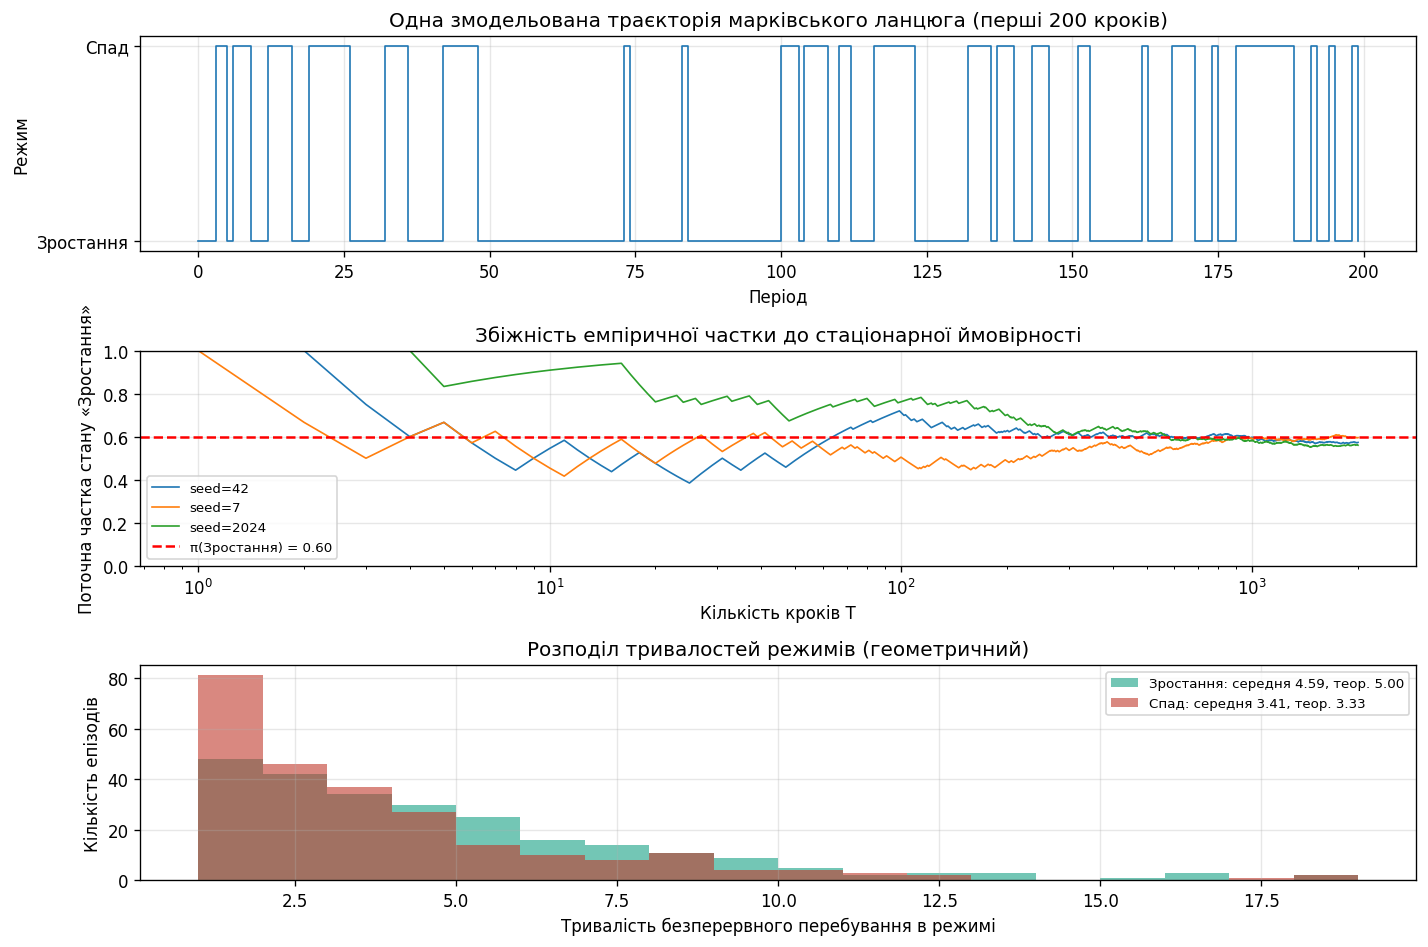

In [10]:
fig, ax = plt.subplots(3, 1, figsize=(12, 8))

ax[0].step(range(200), path_sim[:200], where="post", lw=1)
ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(hidden_states)
ax[0].set_xlabel("Період"); ax[0].set_ylabel("Режим")
ax[0].set_title("Одна змодельована траєкторія марківського ланцюга (перші 200 кроків)")
ax[0].grid(alpha=0.3)

# збіжність поточної частки
for seed, p_ in runs.items():
    running = np.cumsum(p_ == 0) / np.arange(1, T_SIM + 1)
    ax[1].plot(running, lw=1, label=f"seed={seed}")
ax[1].axhline(pi_stationary[0], c="red", ls="--", lw=1.5,
              label=f"π(Зростання) = {pi_stationary[0]:.2f}")
ax[1].set_xlabel("Кількість кроків T"); ax[1].set_ylabel("Поточна частка стану «Зростання»")
ax[1].set_title("Збіжність емпіричної частки до стаціонарної ймовірності")
ax[1].set_xscale("log"); ax[1].set_ylim(0, 1); ax[1].grid(alpha=0.3); ax[1].legend(fontsize=8)

# розподіл тривалостей перебування в режимі
for st, color in [(0, "#16a085"), (1, "#c0392b")]:
  durations, cur = [], 0
  for s in path_sim:
    if s == st:
      cur += 1
    elif cur:
      durations.append(cur); cur = 0

  if cur:
    durations.append(cur)
  ax[2].hist(durations, bins=range(1, 20), alpha=0.6, color=color,
             label=f"{hidden_states[st]}: середня {np.mean(durations):.2f}, "
             f"теор. {1/(1-A[st,st]):.2f}")

ax[2].set_xlabel("Тривалість безперервного перебування в режимі")
ax[2].set_ylabel("Кількість епізодів")
ax[2].set_title("Розподіл тривалостей режимів (геометричний)")
ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()



## **Завдання 5.** Ручний алгоритм Вітербі

HMM із параметрами $\pi,A,B$ із постановки задачі, послідовність спостережень $O=(+,-,+)$.

Параметри:
* $\pi_G=0.6$
* $\pi_R=0.4$
* $a_{GG}=0.8$
* $a_{GR}=0.2$
* $a_{RG}=0.3$
* $a_{RR}=0.7$
* $b_G(+)=0.75$
* $b_G(-)=0.25$
* $b_R(+)=0.20$
* $b_R(-)=0.80$

### 5.1. Ініціалізація $(t=1,o1= +)$


$$
\delta_1(G) = \pi_G\,b_G(+) = 0.6 \times 0.75 = 0.450000$$
$$\delta_1(R) = \pi_R\,b_R(+) = 0.4 \times 0.20 = 0.080000
$$

$𝛹_1$ не визначена - попереднього стану не існує.




### 5.2. Друге спостереження $(t=2,o_2=-)$

**Перехід у стан $G$.** Два кандидати:
$$\delta_1(G)\,a_{GG} = 0.450000 \times 0.8 = 0.360000$$
$$\delta_1(R)\,a_{RG} = 0.080000 \times 0.3 = 0.024000$$

Більший - перший, отже $\psi_2(G) = G$. Враховуємо емісію спостереження $-$:
$$\delta_2(G) = 0.360000 \times b_G(-) = 0.360000 \times 0.25 = 0.090000$$

**Перехід у стан $R$.** Два кандидати:
$$\delta_1(G)\,a_{GR} = 0.450000 \times 0.2 = 0.090000$$
$$\delta_1(R)\,a_{RR} = 0.080000 \times 0.7 = 0.056000$$

Більший - перший, отже $\psi_2(R) = G$. Враховуємо емісію:
$$\delta_2(R) = 0.090000 \times b_R(-) = 0.090000 \times 0.80 = 0.072000$$

### 5.3. Третє спостереження $(t=3,o_3= +)$


**Перехід у стан $G$:**
$$\delta_2(G)\,a_{GG} = 0.090000 \times 0.8 = 0.072000$$
$$\delta_2(R)\,a_{RG} = 0.072000 \times 0.3 = 0.021600$$
Максимум — перший, $\psi_3(G) = G$:
$$\delta_3(G) = 0.072000 \times b_G(+) = 0.072000 \times 0.75 = 0.054000$$

**Перехід у стан $R$:**
$$\delta_2(G)\,a_{GR} = 0.090000 \times 0.2 = 0.018000$$
$$\delta_2(R)\,a_{RR} = 0.072000 \times 0.7 = 0.050400$$
Максимум - **другий**, $\psi_3(R) = R$:
$$\delta_3(R) = 0.050400 \times b_R(+) = 0.050400 \times 0.20 = 0.010080$$

### 5.4. Завершення і зворотний хід

$$z_3^* = \arg\max_j \delta_3(j) = \arg\max\{0.054000,\ 0.010080\} = G$$
$$z_2^* = \psi_3(z_3^*) = \psi_3(G) = G$$
$$z_1^* = \psi_2(z_2^*) = \psi_2(G) = G$$

### Повна таблиця розрахунків

| $t$ | $o_t$ | $\delta_t(G)$ | $\delta_t(R)$ | ⠀⠀⠀$\psi_t(G)$⠀⠀ |⠀⠀⠀$\psi_t(R)$⠀⠀ |
|---|---|---|---|---|---|
| 1 | $+$ | 0.450000 | 0.080000 | — | — |
| 2 | $-$ | 0.090000 | 0.072000 | $G$ | $G$ |
| 3 | $+$ | 0.054000 | 0.010080 | $G$ | $R$ |



### 5.5. Відповідь

$$\boxed{Z^* = (G,\ G,\ G)} \qquad P(Z^*, O) = \delta_3(G) = 0.054000$$

Найімовірніша послідовність прихованих режимів - **зростання, зростання, зростання**.

**Змістовна інтерпретація.** Цікаво, що в момент $t=2$ спостерігалася **негативна** дохідність, яка сама по собі значно типовіша для режиму спаду ($b_R(-) = 0.80$ проти $b_G(-) = 0.25$). Проте алгоритм усе одно відносить цей момент до режиму зростання. Причина - **інерційність ланцюга**: перехід $G \to R$ коштує множника $0.2$, а подальший перехід $R \to G$ - ще $0.3$, тобто "зайти і вийти" зі спаду обходиться у $0.2 \times 0.3 = 0.06$, тоді як залишитися у зростанні коштує $0.8 \times 0.8 = 0.64$. Виграш у правдоподібності емісії ($0.80$ проти $0.25$, тобто у 3.2 раза) не компенсує програшу на переходах (у 10.7 раза). Модель трактує один негативний день як **шум усередині періоду зростання**, а не як повноцінну зміну режиму.## Відповідь

$$\boxed{Z^* = (G,\ G,\ G)} \qquad P(Z^*, O) = \delta_3(G) = 0.054000$$

Найімовірніша послідовність прихованих режимів — **зростання, зростання, зростання**.

**Змістовна інтерпретація.** Цікаво, що в момент $t=2$ спостерігалася **негативна** дохідність, яка сама по собі значно типовіша для режиму спаду ($b_R(-) = 0.80$ проти $b_G(-) = 0.25$). Проте алгоритм усе одно відносить цей момент до режиму зростання. Причина — **інерційність ланцюга**: перехід $G \to R$ коштує множника $0.2$, а подальший перехід $R \to G$ — ще $0.3$, тобто «зайти і вийти» зі спаду обходиться у $0.2 \times 0.3 = 0.06$, тоді як залишитися у зростанні коштує $0.8 \times 0.8 = 0.64$. Виграш у правдоподібності емісії ($0.80$ проти $0.25$, тобто у 3.2 раза) не компенсує програшу на переходах (у 10.7 раза). Модель трактує один негативний день як **шум усередині періоду зростання**, а не як повноцінну зміну режиму.

### Чому стан із найбільшою ймовірністю в певний момент окремо не завжди утворює найімовірніший глобальний шлях

Бо це два **різні критерії оптимальності**, які відповідають на різні запитання:

* **Поточкове декодування** (posterior / MAP-декодування) для кожного моменту $t$ окремо шукає $\arg\max_j P(Z_t = j \mid O)$ - апостеріорний маргінал, який обчислюється алгоритмом "вперед-назад". Цей критерій **максимізує очікувану кількість правильно вгаданих станів**.
* **Алгоритм Вітербі** шукає $\arg\max_{Z} P(Z \mid O)$ - найімовірнішу послідовність **цілком**. Цей критерій максимізує ймовірність того, що вгадано **весь шлях одразу**.

Причина розбіжності у тому, що поточкове декодування **ігнорує ймовірності переходів між сусідніми моментами**. Воно обирає стани незалежно один від одного, тому склеєна з них послідовність може містити переходи, які є малоймовірними або **взагалі неможливими**. Якщо, скажімо, $a_{RG} = 0$, то поточкове декодування цілком може видати шлях $\dots R, G \dots$, імовірність якого дорівнює **точно нулю**.

Формально: максимум суми (по всіх шляхах, що проходять через даний стан) не збігається з максимумом окремого доданка. Вітербі максимізує один доданок - конкретний шлях; поточкове декодування максимізує суму всіх шляхів через дану точку.

Для нашої задачі $O = (+,-,+)$ обидва критерії дають однакову відповідь $(G,G,G)$ - послідовність коротка, а ланцюг однозначно інерційний. Нижче наведено мінімальний приклад, де вони **розходяться**.

### Апостеріорні ймовірності (алгоритм "вперед-назад")

In [11]:
def forward_backward(pi, A, B, obs):
  # повертає α, β, γ (апостеріорні маргінали) та P(O)
  T, N = len(obs), len(pi)
  alpha = np.zeros((T, N)); beta = np.zeros((T, N))
  alpha[0] = pi * B[:, obs[0]]
  for t in range(1, T):
    alpha[t] = (alpha[t - 1] @ A) * B[:, obs[t]]
  beta[-1] = 1.0
  for t in range(T - 2, -1, -1):
    beta[t] = A @ (B[:, obs[t + 1]] * beta[t + 1])
  P_O = alpha[-1].sum()
  gamma = (alpha * beta) / P_O
  return alpha, beta, gamma, P_O


alpha, beta, gamma, P_O = forward_backward(pi, A, B, obs_idx)
print("P(O) =", P_O, "  (сумарна ймовірність спостережень за всіма шляхами)")
print("\nАпостеріорні ймовірності γ_t(j) = P(Z_t = j | O):\n")
print(pd.DataFrame(gamma, columns=hidden_states,
                   index=[f"t={t+1}, o={observations[t]}" for t in range(len(obs_idx))]
                   ).round(6).to_string())

print("\nпоточкове декодування:", [hidden_states[i] for i in gamma.argmax(1)])
print("шлях Вітербі         :", ["Зростання"] * 3)
print("\nДля цієї задачі обидва критерії збігаються.")
print(f"Проте зауважте: у момент t=2 апостеріорна ймовірність зростання "
      f"{gamma[1,0]:.4f} лише трохи більша за {gamma[1,1]:.4f}, тобто")
print("спостереження '−' справді схиляє оцінку до спаду, але інерція ланцюга переважає.")



P(O) = 0.10407200000000001   (сумарна ймовірність спостережень за всіма шляхами)

Апостеріорні ймовірності γ_t(j) = P(Z_t = j | O):

          Зростання     Спад
t=1, o=+   0.805980 0.194020
t=2, o=-   0.590361 0.409639
t=3, o=+   0.805980 0.194020

поточкове декодування: ['Зростання', 'Зростання', 'Зростання']
шлях Вітербі         : ['Зростання', 'Зростання', 'Зростання']

Для цієї задачі обидва критерії збігаються.
Проте зауважте: у момент t=2 апостеріорна ймовірність зростання 0.5904 лише трохи більша за 0.4096, тобто
спостереження '−' справді схиляє оцінку до спаду, але інерція ланцюга переважає.


### Контрприклад: поточкове декодування != Вітербі

In [12]:
def viterbi(pi, A, B, obs):
  T, N = len(obs), len(pi)
  delta = np.zeros((T, N)); psi = np.full((T, N), -1, dtype=int)
  delta[0] = pi * B[:, obs[0]]
  for t in range(1, T):
    for j in range(N):
      cand = delta[t - 1] * A[:, j]
      psi[t, j] = np.argmax(cand)
      delta[t, j] = np.max(cand) * B[j, obs[t]]
  path = np.zeros(T, dtype=int); path[-1] = np.argmax(delta[-1])
  for t in range(T - 1, 0, -1):
    path[t - 1] = psi[t, path[t]]
  return delta, psi, path


def path_probability(pi, A, B, obs, path):
  p = pi[path[0]] * B[path[0], obs[0]]
  for t in range(1, len(obs)):
    p *= A[path[t - 1], path[t]] * B[path[t], obs[t]]
  return p


# ще інерційніший ланцюг і чотири спостереження зі змінним знаком
pi_c = np.array([0.5, 0.5])
A_c = np.array([[0.95, 0.05],
                [0.15, 0.85]])
B_c = np.array([[0.80, 0.20],
                [0.25, 0.75]])

obs_c = [0, 1, 0, 1]    # + - + -

_, _, gamma_c, _ = forward_backward(pi_c, A_c, B_c, obs_c)
_, _, path_c = viterbi(pi_c, A_c, B_c, obs_c)
map_c = list(gamma_c.argmax(1))

print("Контрприклад: O = (+, −, +, −), дуже інерційний ланцюг")
print("A =\n", A_c, "\nB =\n", B_c)
print("\nапостеріорні γ:")
print(pd.DataFrame(gamma_c, columns=hidden_states,
                   index=[f"t={t+1}" for t in range(4)]).round(6).to_string())
print("\nпоточкове декодування:", [hidden_states[i] for i in map_c],
      f"  P(шлях, O) = {path_probability(pi_c, A_c, B_c, obs_c, map_c):.8f}")
print("шлях Вітербі        :", [hidden_states[i] for i in path_c],
      f"  P(шлях, O) = {path_probability(pi_c, A_c, B_c, obs_c, list(path_c)):.8f}")
print(f"\nШлях Вітербі ймовірніший у "
      f"{path_probability(pi_c,A_c,B_c,obs_c,list(path_c))/path_probability(pi_c,A_c,B_c,obs_c,map_c):.1f} разів!")
print("\nПоточково в кожен момент трохи ймовірніший той режим, що відповідає знаку дня,")
print("тож склеєна послідовність 'скаче' G-R-G-R. Але кожне таке перемикання коштує")
print("множника 0.05 або 0.15, і разом вони знищують виграш від кращих емісій.")
print("Вітербі натомість каже: ринок увесь час зростав, а два від'ємні дні — це шум.")



Контрприклад: O = (+, −, +, −), дуже інерційний ланцюг
A =
 [[0.95 0.05]
 [0.15 0.85]] 
B =
 [[0.8  0.2 ]
 [0.25 0.75]]

апостеріорні γ:
     Зростання     Спад
t=1   0.535336 0.464664
t=2   0.474375 0.525625
t=3   0.537373 0.462627
t=4   0.469587 0.530413

поточкове декодування: ['Зростання', 'Спад', 'Зростання', 'Спад']   P(шлях, O) = 0.00006750
шлях Вітербі        : ['Зростання', 'Зростання', 'Зростання', 'Зростання']   P(шлях, O) = 0.01097440

Шлях Вітербі ймовірніший у 162.6 разів!

Поточково в кожен момент трохи ймовірніший той режим, що відповідає знаку дня,
тож склеєна послідовність 'скаче' G-R-G-R. Але кожне таке перемикання коштує
множника 0.05 або 0.15, і разом вони знищують виграш від кращих емісій.
Вітербі натомість каже: ринок увесь час зростав, а два від'ємні дні — це шум.


## **Завдання 6.** Власна програма реалізація Вітербі

In [14]:
hidden_states_short = ["Зростання", "Спад"]
observations = ["+", "-", "+"]

pi_v = np.array([0.6, 0.4])
A_v = np.array([[0.8, 0.2],
                [0.3, 0.7]])
B_dict = {"+": np.array([0.75, 0.20]),    # P(+|G), P(+|R)
          "-": np.array([0.25, 0.80])}    # P(-|G), P(-|R)

T = len(observations)
N = len(hidden_states_short)

delta = np.zeros((T, N))
psi = np.full((T, N), -1, dtype=int)

# 1. Ініціалізація
delta[0] = pi_v * B_dict[observations[0]]

# 2. Рекурсія
for t in range(1, T):
  for j in range(N):
    candidates = delta[t - 1] * A_v[:, j]
    psi[t, j] = np.argmax(candidates)
    delta[t, j] = np.max(candidates) * B_dict[observations[t]][j]


# 3. Вибір найкращого останнього стану
path = np.zeros(T, dtype=int)
path[-1] = np.argmax(delta[-1])

# 4. Зворотний хід
for t in range(T - 1, 0, -1):
  path[t - 1] = psi[t, path[t]]


delta_df = pd.DataFrame(delta,
                        index=[f"t={t+1}, o={observations[t]}" for t in range(T)],
                        columns=hidden_states_short)
psi_df = pd.DataFrame(psi,
                      index=[f"t={t+1}, o={observations[t]}" for t in range(T)],
                      columns=hidden_states_short)

print("Таблиця delta:")
print(delta_df.round(6).to_string())
print("\nТаблиця psi (індекси попередніх станів):")
print(psi_df.to_string())

psi_names = pd.DataFrame(
    [["—" if psi[t, j] == -1 else hidden_states_short[psi[t, j]] for j in range(N)]
     for t in range(T)],
    index=[f"t={t+1}, o={observations[t]}" for t in range(T)],
    columns=hidden_states_short)
print("\nТаблиця psi (з назвами станів):")
print(psi_names.to_string())

print("\nНайімовірніший шлях:", [hidden_states_short[i] for i in path])
print("Імовірність знайденого шляху:", delta[-1, path[-1]])



Таблиця delta:
          Зростання     Спад
t=1, o=+   0.450000 0.080000
t=2, o=-   0.090000 0.072000
t=3, o=+   0.054000 0.010080

Таблиця psi (індекси попередніх станів):
          Зростання  Спад
t=1, o=+         -1    -1
t=2, o=-          0     0
t=3, o=+          0     1

Таблиця psi (з назвами станів):
          Зростання       Спад
t=1, o=+          —          —
t=2, o=-  Зростання  Зростання
t=3, o=+  Зростання       Спад

Найімовірніший шлях: ['Зростання', 'Зростання', 'Зростання']
Імовірність знайденого шляху: 0.05399999999999999


### Звірка із ручними обчисленнями із Завдання 5

In [15]:
manual_delta = np.array([[0.450000, 0.080000],
                         [0.090000, 0.072000],
                         [0.054000, 0.010080]])

manual_psi = np.array([[-1, -1],
                       [0, 0],
                       [0, 1]])
manual_path = [0, 0, 0]

print("Звірка ручного розрахунку з програмним\n")
cmp = pd.DataFrame({
    "δ вручну": manual_delta.ravel(),
    "δ програмно": delta.ravel(),
    "різниця": np.abs(manual_delta - delta).ravel()},
      index=[f"t={t+1}, {s}" for t in range(T) for s in hidden_states_short])

print(cmp.to_string())

assert np.allclose(manual_delta, delta, atol=1e-9), "δ не збігається!"
assert np.array_equal(manual_psi, psi), "ψ не збігається!"
assert list(path) == manual_path, "шлях не збігається!"
print("\n[OK] Ручні таблиці δ і ψ та шлях повністю збігаються з програмними.")
print(f"    максимальна розбіжність δ: {np.abs(manual_delta - delta).max():.2e}")



Звірка ручного розрахунку з програмним

                δ вручну  δ програмно  різниця
t=1, Зростання  0.450000     0.450000 0.000000
t=1, Спад       0.080000     0.080000 0.000000
t=2, Зростання  0.090000     0.090000 0.000000
t=2, Спад       0.072000     0.072000 0.000000
t=3, Зростання  0.054000     0.054000 0.000000
t=3, Спад       0.010080     0.010080 0.000000

[OK] Ручні таблиці δ і ψ та шлях повністю збігаються з програмними.
    максимальна розбіжність δ: 5.55e-17


## **Завдання 7.** Візуалізація решітки Вітербі

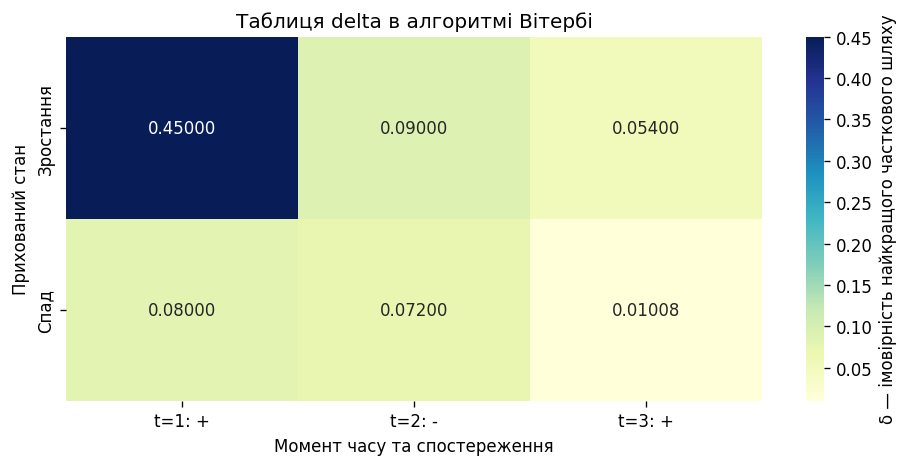

In [16]:
plt.figure(figsize=(8, 4))
sns.heatmap(delta.T, annot=True, fmt=".5f", cmap="YlGnBu",
            xticklabels=[f"t={t+1}: {observations[t]}" for t in range(T)],
            yticklabels=hidden_states_short,
            cbar_kws={"label": "δ — імовірність найкращого часткового шляху"})
plt.xlabel("Момент часу та спостереження")
plt.ylabel("Прихований стан")
plt.title("Таблиця delta в алгоритмі Вітербі")
plt.tight_layout()
plt.show()


### Наймовірніша траєкторія

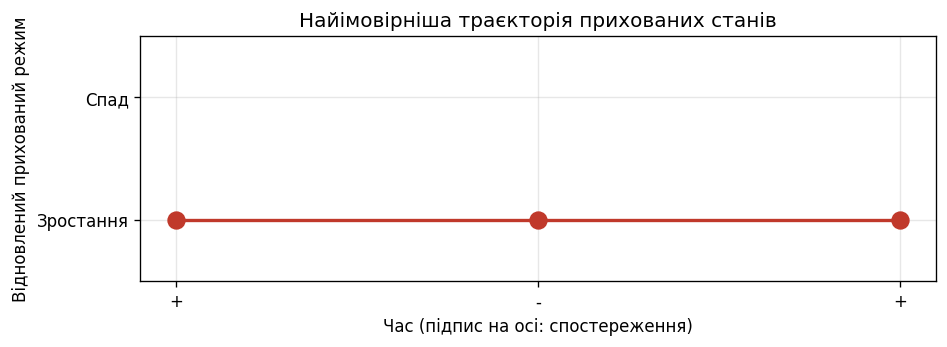

Спостереження: ['+', '-', '+']
Приховані стани за Вітербі: ['Зростання', 'Зростання', 'Зростання']


In [17]:
decoded_names = [hidden_states_short[i] for i in path]

plt.figure(figsize=(8, 3))
plt.plot(range(1, T + 1), path, marker="o", ms=10, linewidth=2, color="#c0392b")
plt.yticks(range(N), hidden_states_short)
plt.xticks(range(1, T + 1), observations)
plt.xlabel("Час (підпис на осі: спостереження)")
plt.ylabel("Відновлений прихований режим")
plt.title("Найімовірніша траєкторія прихованих станів")
plt.ylim(-0.5, N - 0.5)
plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("Спостереження:", observations)
print("Приховані стани за Вітербі:", decoded_names)


### Що саме демонструє кожна з двох візуалізауій

**Теплова карта таблиці $\delta$** показує **весь простір пошуку** - усі $N \times T$ комірок решітки з ймовірністю найкращого часткового шляху, що веде в кожну з них. З неї видно:
* наскільки "перспективним" є кожен стан у кожен момент часу: світліші комірки - менш ймовірні часткові шляхи, темніші - більш імовірні;
* **конкуренцію між станами**: у момент $t=2$ значення $0.090000$ і $0.072000$ дуже близькі, тобто рішення алгоритму на цьому кроці було «на межі». У момент $t=3$ розрив уже п'ятикратний ($0.054$ проти $0.0101$) - рішення впевнене;
* **систематичне зменшення** всіх значень із часом: кожен крок домножує на ймовірності $< 1$, тому числа швидко спадають. Саме це й робить необхідним логарифмічний масштаб для довгих послідовностей (Завдання 9).

Важливо: теплова карта показує $\delta$, а **не** остаточну відповідь. Найбільше значення в кожному стовпці не обов'язково належить оптимальному шляху, бо вибір робиться лише на останньому кроці з подальшим зворотним ходом за $\psi$.

**Графік траєкторії** показує **результат** - єдину відновлену послідовність після зворотного ходу. Це та сама інформація, що й у відповіді $Z^* = (G,G,G)$, але в наочній формі: видно, коли саме модель вважає, що режим змінювався. У нашому випадку лінія горизонтальна - модель стверджує, що режим не змінювався жодного разу, попри від'ємну дохідність у другий день.

Разом вони відповідають на два різні запитання: карта - "як алгоритм дійшов висновку і наскільки він був упевнений", графік - "який саме висновок".

## **Завдання 8.** Перевірка через `hmmlearn`

In [18]:
from hmmlearn import hmm


# кодування спостережень "+" -> 0, "-" -> 1
obs_to_int = {"+": 0, "-": 1}
X = np.array([[obs_to_int[o]] for o in observations])

model = hmm.CategoricalHMM(n_components=2, init_params="", params="",
                           algorithm="viterbi")
model.startprob_ = pi_v
model.transmat_ = A_v
model.emissionprob_ = np.array([[0.75, 0.25],
                                [0.20, 0.80]])

logprob, decoded_hmmlearn =  model.decode(X, algorithm="viterbi")

print("Логарифм імовірності найкращого шляху:", logprob)
print("Імовірність exp(logprob):", np.exp(logprob))
print("δ_T(z*) з власної реалізації:", delta[-1, path[-1]])
print("розбіжність:", abs(np.exp(logprob) - delta[-1, path[-1]]), "\n")
print("Шлях hmmlearn:", [hidden_states_short[i] for i in decoded_hmmlearn])
print("Власний шлях :", [hidden_states_short[i] for i in path])

assert np.array_equal(path, decoded_hmmlearn), \
    "Шляхи не збігаються. Перевірте кодування емісій та параметри моделі."
print("\nПеревірка успішна: результати збігаються.")



Логарифм імовірності найкращого шляху: -2.9187712324178623
Імовірність exp(logprob): 0.05400000000000002
δ_T(z*) з власної реалізації: 0.05399999999999999
розбіжність: 2.7755575615628914e-17 

Шлях hmmlearn: ['Зростання', 'Зростання', 'Зростання']
Власний шлях : ['Зростання', 'Зростання', 'Зростання']

Перевірка успішна: результати збігаються.


### Чому бібліотечний результат не замінює ручного аналізу таблиць $\delta$ і $\psi$

`hmmlearn` повертає **лише кінцевий результат** - декодовану послідовність і логарифм її ймовірності. Усе проміжне залишається всередині бібліотеки. Ручний аналіз дає принципово іншу інформацію:


1. **Розуміння механізму.** Таблиці показують, що Вітербі - це динамічне програмування: на кожному кроці зберігається лише $N$ найкращих часткових шляхів замість $N^t$ усіх можливих.
2. **Упевненість рішення.** З $\delta$ видно, наскільки близькими були конкуруючі варіанти. У нашій задачі на кроці $t=2$ значення відрізнялися лише на 25% ($0.090$ проти $0.072$) - рішення було хитким, і невелика зміна параметрів могла б його перевернути. Один лише кінцевий шлях цього не повідомляє.
3. **Діагностика помилок.** Якщо результат виглядає дивним, причину шукають саме в таблицях: де саме виникла причина. З одного лише вихідного вектора зневадити модель неможливо.
4. **Перевірка самої бібліотеки.** Бібліотека може мати інші угоди щодо індексації, форми вхідних даних чи орієнтації матриці емісій. Збіг із незалежним ручним розрахунком - єдиний спосіб переконатися, що параметри передано правильно. Тут це підтверджено: $$\exp(\text{logprob}) = 0.054000 = \delta_3(G).$$
5. **Межі застосовності.** Знаючи структуру $\delta$, зрозуміло, чому для довгих послідовностей потрібні логарифми (Завдання 9) - із самої бібліотеки це не видно.

### Які параметри HMM було задано вручну, а не оцінено з даних

**Усі параметри моделі задано вручну** - жоден не оцінювався з даних:

| Параметр | Значення | Джерело |
|---|---|---|
| $\pi$ (`startprob_`) | $(0.6,\ 0.4)$ | задано в умові |
| $A$ (`transmat_`) | $\begin{pmatrix}0.8&0.2\\0.3&0.7\end{pmatrix}$ | задано в умові |
| $B$ (`emissionprob_`) | $\begin{pmatrix}0.75&0.25\\0.20&0.80\end{pmatrix}$ | задано в умові |


Це означає, що ми розв'язували **лише третю задачу HMM - декодування** (знайти $Z^*$ за відомими $\pi, A, B$ і $O$). Дві інші класичні задачі не розв'язувалися:
* **задача оцінювання** - обчислити $P(O)$ за моделлю (алгоритм «вперед»; ми обчислили її окремо в Завданні 5: $P(O) = 0.104072$);
* **задача навчання** - оцінити $\pi, A, B$ з даних (алгоритм Баума–Велча, тобто EM). Для цього знадобилася б довга послідовність спостережень і виклик `model.fit(X)`.

## **Завдання 9.** Робота в логарифмічному масштабі

### Навіщо це потрібно

Значення $\delta_t(j)$ є добутком $2t$ ймовірностей, кожна з яких менша за одиницю. Для послідовності довжини $T$ порядок величини становить приблизно $p^{2T}$. Уже при $T \approx 300$ і типових $p \approx 0.5$ результат виходить за межі найменшого нормального числа типу `float64` ($\approx 2.2\cdot10^{-308}$) і округлюється до **нуля** - виникає **антипереповнення** (arithmetic underflow). Після цього всі значення стають нулями, `argmax` повертає довільний індекс, і алгоритм видає безглуздий результат.

Логарифмування усуває проблему, бо перетворює добутки на суми: замість $10^{-400}$ зберігається число $\approx -921$, яке чудово вміщується у `float64`.

## Які властивості використовуються

$$\log(xy) = \log x + \log y$$
$$\log\bigl(\max_i x_i\bigr) = \max_i \log(x_i)$$

Друга властивість справедлива тому, що логарифм - **строго зростаюча** функція, отже вона зберігає порядок: $x_i > x_j \Leftrightarrow \log x_i > \log x_j$. Саме тому $\arg\max$ **не змінюється** при логарифмуванні - а це критично, бо від нього залежить таблиця $\psi$ і, зрештою, увесь відновлений шлях.

### Вітербі в логарифмічному масштабі

In [19]:
def viterbi_log(pi, A, B, observations):
  # Вітербі в логарифмічному масштабі (стійкий до антипереповнення)
  T = len(observations)
  N = len(pi)

  with np.errstate(divide="ignore"):
    log_pi = np.log(pi)
    log_A = np.log(A)

  log_delta = np.full((T, N), -np.inf)
  psi = np.full((T, N), -1, dtype=int)

  with np.errstate(divide="ignore"):
    log_delta[0] = log_pi + np.log(B[observations[0]])

    for t in range(1, T):
      log_emission = np.log(B[observations[t]])
      for j in range(N):
        candidates = log_delta[t - 1] + log_A[:, j]
        psi[t, j] = np.argmax(candidates)
        log_delta[t, j] = np.max(candidates) + log_emission[j]

  path = np.zeros(T, dtype=int)
  path[-1] = np.argmax(log_delta[-1])
  for t in range(T - 1, 0, -1):
    path[t-1] = psi[t, path[t]]

  return log_delta, psi, path


log_delta, log_psi, log_path = viterbi_log(pi_v, A_v, B_dict, observations)

print("Таблиця log_delta:")
print(pd.DataFrame(log_delta, columns=hidden_states_short,
                   index=[f"t={t+1}, o={observations[t]}" for t in range(T)]
                   ).round(6).to_string())

print("\nПеревірка: exp(log_delta) має дорівнювати delta")
print(pd.DataFrame(np.exp(log_delta), columns=hidden_states_short,
                   index=[f"t={t+1}" for t in range(T)]).round(6).to_string())
print("максимальна розбіжність:", np.abs(np.exp(log_delta) - delta).max())

print("\nШлях (лог. масштаб):", [hidden_states_short[i] for i in log_path])
print("Шлях (звичайний)   :", [hidden_states_short[i] for i in path])
print("Чи збігаються шляхи?", np.array_equal(path, log_path))
print("Таблиці ψ однакові? ", np.array_equal(psi, log_psi))



Таблиця log_delta:
          Зростання      Спад
t=1, o=+  -0.798508 -2.525729
t=2, o=-  -2.407946 -2.631089
t=3, o=+  -2.918771 -4.597202

Перевірка: exp(log_delta) має дорівнювати delta
     Зростання     Спад
t=1   0.450000 0.080000
t=2   0.090000 0.072000
t=3   0.054000 0.010080
максимальна розбіжність: 5.551115123125783e-17

Шлях (лог. масштаб): ['Зростання', 'Зростання', 'Зростання']
Шлях (звичайний)   : ['Зростання', 'Зростання', 'Зростання']
Чи збігаються шляхи? True
Таблиці ψ однакові?  True


### Демонстрація антипереповнення на довгій послідовності

In [20]:
rng = np.random.default_rng(0)
LONG = 1500
long_obs = ["+" if rng.random() < 0.5 else "-" for _ in range(LONG)]
long_idx = [obs_to_int[o] for o in long_obs]
B_mat = np.array([[0.75, 0.25], [0.20, 0.80]])

d_long, _, p_long = viterbi(pi_v, A_v, B_mat, long_idx)          # звичайний масштаб
ld_long, _, lp_long = viterbi_log(pi_v, A_v, B_dict, long_obs)   # логарифмічний

zero_rows = np.where((d_long == 0).all(axis=1))[0]
first_zero = int(zero_rows[0]) + 1 if len(zero_rows) else None

print(f"Довжина послідовності: {LONG}")
print(f"Найменше нормальне число float64: {np.finfo(float).tiny:.3e}\n")
print(f"{'крок t':>8}{'δ(G) звичайний':>20}{'log δ(G)':>14}{'exp(log δ)':>16}")
print("-" * 58)
for t in [1, 100, 300, 600, 700, 800, 1000, 1500]:
    i = t - 1
    print(f"{t:>8}{d_long[i,0]:>20.6e}{ld_long[i,0]:>14.2f}"
          f"{np.exp(ld_long[i,0]):>16.6e}")

print(f"\nПерший крок, де δ занулилося повністю: {first_zero}")
print(f"log δ на цьому кроці: {ld_long[first_zero-1]} "
      f"-> справжнє значення ≈ e^{ld_long[first_zero-1].max():.0f}, "
      f"тобто ~10^{ld_long[first_zero-1].max()/np.log(10):.0f}")
print("Це менше за найменше представне число float64, тому результат округлено до 0.")

print(f"\nШлях (звичайний масштаб) збігається з логарифмічним? "
      f"{np.array_equal(p_long, lp_long)}")
print("Після занулення δ усі стани стають рівноцінними (0 == 0), argmax повертає")
print("перший індекс, і зворотний хід відновлює довільний, а не оптимальний шлях.")
print(f"Частка кроків, де шляхи розійшлися: "
      f"{100*np.mean(p_long != lp_long):.1f}%")


Довжина послідовності: 1500
Найменше нормальне число float64: 2.225e-308

  крок t      δ(G) звичайний      log δ(G)      exp(log δ)
----------------------------------------------------------
       1        1.500000e-01         -1.90    1.500000e-01
     100        8.834464e-43        -96.83    8.834464e-43
     300       8.074985e-127       -290.34   8.074985e-127
     600       6.784838e-247       -566.82   6.784838e-247
     700       1.161622e-286       -658.39   1.161622e-286
     800        0.000000e+00       -754.98    0.000000e+00
    1000        0.000000e+00       -943.48    0.000000e+00
    1500        0.000000e+00      -1410.01    0.000000e+00

Перший крок, де δ занулилося повністю: 791
log δ на цьому кроці: [-747.089039 -747.312183] -> справжнє значення ≈ e^-747, тобто ~10^-324
Це менше за найменше представне число float64, тому результат округлено до 0.

Шлях (звичайний масштаб) збігається з логарифмічним? False
Після занулення δ усі стани стають рівноцінними (0 == 0), ar

### Які дві операції у формулі Вітербі змінилися

Порівняємо рекурсію до і після логарифмування

1. **Звичайний масштаб**
* Ініціалізація: $\delta_1(j)=\pi_j\cdot b_j(o_1)$
* Рекурсія: $\delta_t(j)=\left[\max_i\delta_{t-1}(i)\cdot a_{ij}\right]\cdot b_j(o_t)$

2. **Логарифмічний масштаб**
* Ініціалізація: $\log\delta_1(j)=\log\pi_j+\log b_j(o_1)$
* Рекурсія: $\log\delta_t(j)=\left[\max_i(\log\delta_{t-1}(i)+\log a_{ij})\right]+ \log b_j(o_t)$

Змінилося рівно **дві операції**, обидві - множення.

**Практичні наслідки:** Окрім стійкості до антипереповнення, додавання дешевше за множення на більшості процесорів. Ціна - одноразове обчислення логарифмів і потреба акуратно обробляти нульові ймовірності: $\log 0 = -\infty$, що в NumPy коректно працює в порівняннях і додаванні (`-inf + x = -inf`), але спричиняє попередження, яке придушено через `np.errstate(divide="ignore")`.

Зауважимо, що для алгоритму "вперед" такий простий трюк не працює: там потрібна **сума** ймовірностей, а $\log(x+y) \ne \log x + \log y$. Для нього застосовують прийом `logsumexp`: $\quad\log\sum_i e^{x_i} = x_{\max} + \log\sum_i e^{x_i - x_{\max}}$.

## **10. Індивідуальне завдання.** Варіант 4: Три режими фондового ринку

Задача:

> Побудуйте HMM із трьома прихованими станами: "зростання", "стабільність", "криза". Введіть щонайменше **три категорії спостережень** дохідності та реалізуйте Вітербі.



### 10.1. Приховані стани $(N=3)$

| Позначення | Стан | Економічний зміст |
|---|---|---|
| $G$ | **Зростання** | бичачий ринок: стійке підвищення котирувань, оптимізм інвесторів |
| $S$ | **Стабільність** | бічний тренд: ринок коливається без вираженого напрямку |
| $C$ | **Криза** | ведмежий ринок: падіння, панічні розпродажі, висока волатильність |


### 10.2. Спостереження $M=4$

Замість простого знаку дохідності вводимо чотири категорії за величиною щоденної дохідності $r$:

| Позн. | Категорія | ⠀⠀⠀Діапазон⠀⠀|
|---|---|---|
| **СЗ** | сильне зростання | $r>+1\%$ |
| **ПЗ** | помірне зростання | $0 < r \le +1\%$ |
| **ПС** | помірний спад | $-1\% \le r < 0$ |
| **СС** | сильний спад | $r < -1\%$


Чотири категорії замість двох дають моделі змогу розрізняти не лише напрям, а й **величину** руху - а саме величина найкраще відрізняє кризу від звичайного спаду.

### 10.3. Початковий розподіл

$$
\pi=\left(0.5\quad0.4\quad0.1\right)
$$

Припускаємо, що на початку спостереження ринок наймовірніше зростає або стабільний, а криза малоймовірна.

### 10.4. Матриця переходів

$$A = \begin{array}{c|ccc} & G & S & C \\\hline G & 0.80 & 0.17 & 0.03 \\ S & 0.15 & 0.75 & 0.10 \\ C & 0.05 & 0.30 & 0.65 \end{array}$$

### 10.5. Матриця емісій

$$B = \begin{array}{c|cccc} & \text{СЗ} & \text{ПЗ} & \text{ПС} & \text{СС} \\\hline G & 0.35 & 0.40 & 0.20 & 0.05 \\ S & 0.10 & 0.40 & 0.40 & 0.10 \\ C & 0.05 & 0.15 & 0.30 & 0.50 \end{array}$$

1. у режимі **зростання** переважають позитивні дні ($0.35 + 0.40 = 0.75$), але окремі негативні трапляються.
2. у режимі **стабільності** розподіл **симетричний** ($0.10/0.40$ проти $0.40/0.10$) і сконцентрований у помірних категоріях - це визначальна ознака бічного тренду: мала волатильність.
3. у режимі **кризи** домінують сильні падіння ($0.50$). Прикметно, що $b_C(\text{СЗ}) = 0.05 > 0$: під час криз трапляються різкі відскоки.

In [21]:
states3 = ["Зростання", "Стабільність", "Криза"]
obs3_names = ["СЗ", "ПЗ", "ПС", "СС"]

pi3 = np.array([0.5, 0.4, 0.1])
A3 = np.array([[0.80, 0.17, 0.03],
               [0.15, 0.75, 0.10],
               [0.05, 0.30, 0.65]])

B3 = np.array([[0.35, 0.40, 0.20, 0.05],
               [0.10, 0.40, 0.40, 0.10],
               [0.05, 0.15, 0.30, 0.50]])

print("π =", pi3, "  сума =", pi3.sum())
print("\nA =")
print(pd.DataFrame(A3, index=states3, columns=states3).to_string())
print("суми рядків A:", A3.sum(axis=1))
print("\nB =")
print(pd.DataFrame(B3, index=states3, columns=obs3_names).to_string())
print("суми рядків B:", B3.sum(axis=1))

assert np.allclose(A3.sum(axis=1), 1.0) and np.allclose(B3.sum(axis=1), 1.0) \
    and np.isclose(pi3.sum(), 1.0)
print("\n[OK] усі розподіли нормовані")

print("\nОчікувана тривалість режимів:")
for i, s in enumerate(states3):
  print(f"  {s:14s}: {1/(1-A3[i,i]):.2f} періодів")


π = [0.5 0.4 0.1]   сума = 1.0

A =
              Зростання  Стабільність    Криза
Зростання      0.800000      0.170000 0.030000
Стабільність   0.150000      0.750000 0.100000
Криза          0.050000      0.300000 0.650000
суми рядків A: [1. 1. 1.]

B =
                   СЗ       ПЗ       ПС       СС
Зростання    0.350000 0.400000 0.200000 0.050000
Стабільність 0.100000 0.400000 0.400000 0.100000
Криза        0.050000 0.150000 0.300000 0.500000
суми рядків B: [1. 1. 1.]

[OK] усі розподіли нормовані

Очікувана тривалість режимів:
  Зростання     : 5.00 періодів
  Стабільність  : 4.00 періодів
  Криза         : 2.86 періодів


### Стаціонарний розподіл тривимірного ланцюга

In [22]:
n3 = 3
M3 = A3.T - np.eye(n3)
M3[-1] = np.ones(n3)
b3 = np.zeros(n3)
b3[-1] = 1

pi3_stat = np.linalg.solve(M3, b3)

print("Стаціонарний розподіл:")
print(pd.DataFrame({"Стан": states3, "π*": pi3_stat}).round(6).to_string(index=False))
print("\nперевірка π@A - π:", np.abs(pi3_stat @ A3 - pi3_stat).max())
print("сума:", pi3_stat.sum())
print("\nІнтерпретація: у довгостроковому режимі ринок перебуває")
for s, p in zip(states3, pi3_stat):
  print(f"  у стані «{s}» — {100*p:.1f}% часу (повернення кожні {1/p:.2f} періоди)")


Стаціонарний розподіл:
        Стан       π*
   Зростання 0.382060
Стабільність 0.455150
       Криза 0.162791

перевірка π@A - π: 2.7755575615628914e-17
сума: 1.0

Інтерпретація: у довгостроковому режимі ринок перебуває
  у стані «Зростання» — 38.2% часу (повернення кожні 2.62 періоди)
  у стані «Стабільність» — 45.5% часу (повернення кожні 2.20 періоди)
  у стані «Криза» — 16.3% часу (повернення кожні 6.14 періоди)


### Симуляція траєкторії тривимірного ланцюга

        Стан  Емпірична частка  Стаціонарна ймовірність  Різниця
   Зростання          0.343000                 0.382100 0.039100
Стабільність          0.481700                 0.455100 0.026500
       Криза          0.175300                 0.162800 0.012500


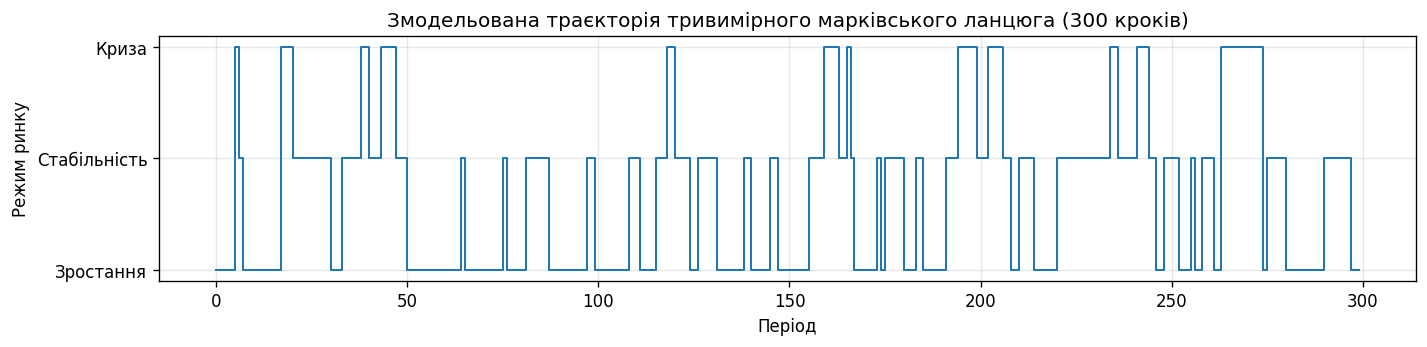

In [23]:
T3_SIM = 3000
path3_sim = simulate_chain(A3, T3_SIM, seed=2024)
emp3 = np.bincount(path3_sim, minlength=3) / T3_SIM

print(pd.DataFrame({"Стан": states3,
                    "Емпірична частка": emp3,
                    "Стаціонарна ймовірність": pi3_stat,
                    "Різниця": np.abs(emp3 - pi3_stat)}).round(4).to_string(index=False))

plt.figure(figsize=(12, 3))
plt.step(range(300), path3_sim[:300], where="post", lw=1.2)
plt.yticks(range(3), states3)
plt.xlabel("Період"); plt.ylabel("Режим ринку")
plt.title("Змодельована траєкторія тривимірного марківського ланцюга (300 кроків)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Вітербі для пос-ті спостережень

In [25]:
seq3 = ["ПЗ", "СЗ", "ПЗ", "ПС", "СС", "СС", "ПС", "СС", "ПЗ", "ПЗ", "СЗ", "ПЗ"]
obs3_idx = [obs3_names.index(o) for o in seq3]

delta3, psi3, path3 = viterbi(pi3, A3, B3, obs3_idx)
alpha3, beta3, gamma3, P_O3 = forward_backward(pi3, A3, B3, obs3_idx)

print("Послідовність спостережень (12 днів):")
print("  ", " ".join(f"{o:>3s}" for o in seq3))
print("\nВідновлені приховані режими (Вітербі):")
print("  ", " ".join(f"{states3[i][:3]:>3s}" for i in path3))
print("\nрозгорнуто:")
for t, (o, z) in enumerate(zip(seq3, path3), 1):
  print(f"  день {t:2d}: спостереження {o:3s} -> режим '{states3[z]}'")

print(f"\nP(Z*, O) = {delta3[-1].max():.6e}")
print(f"P(O)     = {P_O3:.6e}")
print(f"P(Z*|O)  = {delta3[-1].max()/P_O3:.6f}  "
      f"<- частка найкращого шляху серед усіх 3^12 = {3**12} можливих")

Послідовність спостережень (12 днів):
    ПЗ  СЗ  ПЗ  ПС  СС  СС  ПС  СС  ПЗ  ПЗ  СЗ  ПЗ

Відновлені приховані режими (Вітербі):
   Зро Зро Зро Ста Кри Кри Кри Кри Ста Ста Ста Ста

розгорнуто:
  день  1: спостереження ПЗ  -> режим 'Зростання'
  день  2: спостереження СЗ  -> режим 'Зростання'
  день  3: спостереження ПЗ  -> режим 'Зростання'
  день  4: спостереження ПС  -> режим 'Стабільність'
  день  5: спостереження СС  -> режим 'Криза'
  день  6: спостереження СС  -> режим 'Криза'
  день  7: спостереження ПС  -> режим 'Криза'
  день  8: спостереження СС  -> режим 'Криза'
  день  9: спостереження ПЗ  -> режим 'Стабільність'
  день 10: спостереження ПЗ  -> режим 'Стабільність'
  день 11: спостереження СЗ  -> режим 'Стабільність'
  день 12: спостереження ПЗ  -> режим 'Стабільність'

P(Z*, O) = 1.016490e-09
P(O)     = 1.065077e-07
P(Z*|O)  = 0.009544  <- частка найкращого шляху серед усіх 3^12 = 531441 можливих


### Таблиці $\delta$ та $\psi$ для тривимірної задачі

In [27]:
idx3 = [f"t={t+1}, {seq3[t]}" for t in range(len(seq3))]

print("Таблиця δ:")
print(pd.DataFrame(delta3, index=idx3, columns=states3).to_string())

psi3_names = pd.DataFrame(
    [["—" if psi3[t, j] == -1 else states3[psi3[t, j]] for j in range(3)]
     for t in range(len(seq3))], index=idx3, columns=states3)
print("\nТаблиця ψ (назви попередніх станів):")
print(psi3_names.to_string())


Таблиця δ:
          Зростання  Стабільність    Криза
t=1, ПЗ    0.200000      0.160000 0.015000
t=2, СЗ    0.056000      0.012000 0.000800
t=3, ПЗ    0.017920      0.003808 0.000252
t=4, ПС    0.002867      0.001219 0.000161
t=5, СС    0.000115      0.000091 0.000061
t=6, СС    0.000005      0.000007 0.000020
t=7, ПС    0.000001      0.000002 0.000004
t=8, СС    0.000000      0.000000 0.000001
t=9, ПЗ    0.000000      0.000000 0.000000
t=10, ПЗ   0.000000      0.000000 0.000000
t=11, СЗ   0.000000      0.000000 0.000000
t=12, ПЗ   0.000000      0.000000 0.000000

Таблиця ψ (назви попередніх станів):
             Зростання  Стабільність         Криза
t=1, ПЗ              —             —             —
t=2, СЗ      Зростання  Стабільність  Стабільність
t=3, ПЗ      Зростання     Зростання     Зростання
t=4, ПС      Зростання     Зростання     Зростання
t=5, СС      Зростання  Стабільність  Стабільність
t=6, СС      Зростання  Стабільність         Криза
t=7, ПС      Зростання         Криз

### Візуалізація теплової карти та траєкторії

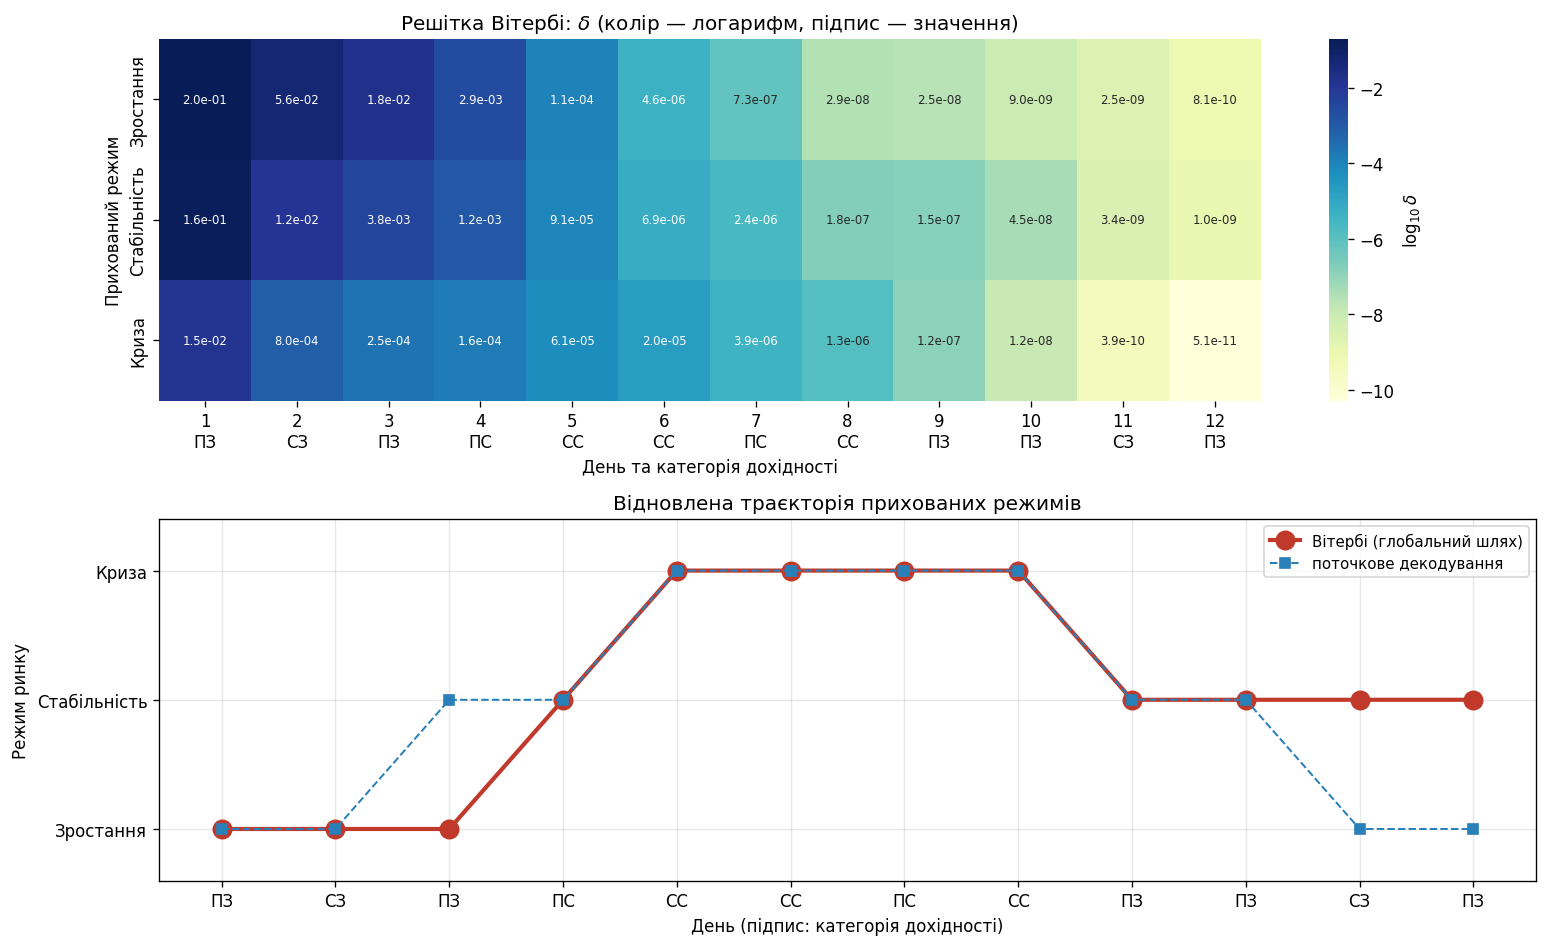

In [28]:
fig, ax = plt.subplots(2, 1, figsize=(13, 8))

with np.errstate(divide="ignore"):
  log_d3 = np.log10(delta3)
sns.heatmap(log_d3.T, annot=delta3.T, fmt=".1e", cmap="YlGnBu", ax=ax[0],
            xticklabels=[f"{t+1}\n{seq3[t]}" for t in range(len(seq3))],
            yticklabels=states3, annot_kws={"size": 7},
            cbar_kws={"label": "$\\log_{10}\\delta$"})
ax[0].set_xlabel("День та категорія дохідності")
ax[0].set_ylabel("Прихований режим")
ax[0].set_title("Решітка Вітербі: $\\delta$ (колір — логарифм, підпис — значення)")

ax[1].plot(range(1, len(seq3) + 1), path3, marker="o", ms=11, lw=2.5,
           color="#c0392b", label="Вітербі (глобальний шлях)")
ax[1].plot(range(1, len(seq3) + 1), gamma3.argmax(1), marker="s", ms=6, lw=1.2,
           ls="--", color="#2980b9", label="поточкове декодування")
ax[1].set_yticks(range(3)); ax[1].set_yticklabels(states3)
ax[1].set_xticks(range(1, len(seq3) + 1)); ax[1].set_xticklabels(seq3)
ax[1].set_xlabel("День (підпис: категорія дохідності)")
ax[1].set_ylabel("Режим ринку")
ax[1].set_title("Відновлена траєкторія прихованих режимів")
ax[1].set_ylim(-0.4, 2.4); ax[1].grid(alpha=0.3); ax[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


### Порівняння з поточковим декодуванням та перевірка `hmmlearn`

In [29]:
map3 = list(gamma3.argmax(1))
print("ПОРІВНЯННЯ ДВОХ КРИТЕРІЇВ ДЕКОДУВАННЯ\n")
cmp3 = pd.DataFrame({
    "день": range(1, len(seq3) + 1),
    "спост.": seq3,
    "Вітербі": [states3[i] for i in path3],
    "поточковий MAP": [states3[i] for i in map3],
    "збіг": ["так" if a == b else "НІ" for a, b in zip(path3, map3)]})
print(cmp3.to_string(index=False))

print(f"\nP(шлях Вітербі, O)   = {path_probability(pi3, A3, B3, obs3_idx, list(path3)):.6e}")
print(f"P(поточковий шлях, O) = {path_probability(pi3, A3, B3, obs3_idx, map3):.6e}")
ratio = path_probability(pi3, A3, B3, obs3_idx, list(path3)) / \
        path_probability(pi3, A3, B3, obs3_idx, map3)
print(f"шлях Вітербі ймовірніший у {ratio:.2f} раза")

# перевірка бібліотекою
X3 = np.array([[i] for i in obs3_idx])
model3 = hmm.CategoricalHMM(n_components=3, init_params="", params="",
                            algorithm="viterbi")
model3.startprob_ = pi3
model3.transmat_ = A3
model3.emissionprob_ = B3
logprob3, dec3 = model3.decode(X3, algorithm="viterbi")

print(f"\nhmmlearn: logprob = {logprob3:.6f}, exp = {np.exp(logprob3):.6e}")
print(f"власна реалізація: {delta3[-1].max():.6e}")
print("шлях hmmlearn:", [states3[i] for i in dec3])
assert np.array_equal(path3, dec3)
print("\n[OK] власна реалізація та hmmlearn збігаються")

# і логарифмічна версія
B3_dict = {o: B3[:, j] for j, o in enumerate(obs3_names)}
ld3, lp3, lpath3 = viterbi_log(pi3, A3, B3_dict, seq3)
assert np.array_equal(path3, lpath3)
print("[OK] логарифмічна версія теж збігається")

ПОРІВНЯННЯ ДВОХ КРИТЕРІЇВ ДЕКОДУВАННЯ

 день спост.      Вітербі поточковий MAP збіг
    1     ПЗ    Зростання      Зростання  так
    2     СЗ    Зростання      Зростання  так
    3     ПЗ    Зростання   Стабільність   НІ
    4     ПС Стабільність   Стабільність  так
    5     СС        Криза          Криза  так
    6     СС        Криза          Криза  так
    7     ПС        Криза          Криза  так
    8     СС        Криза          Криза  так
    9     ПЗ Стабільність   Стабільність  так
   10     ПЗ Стабільність   Стабільність  так
   11     СЗ Стабільність      Зростання   НІ
   12     ПЗ Стабільність      Зростання   НІ

P(шлях Вітербі, O)   = 1.016490e-09
P(поточковий шлях, O) = 7.115433e-10
шлях Вітербі ймовірніший у 1.43 раза

hmmlearn: logprob = -20.706910, exp = 1.016490e-09
власна реалізація: 1.016490e-09
шлях hmmlearn: ['Зростання', 'Зростання', 'Зростання', 'Стабільність', 'Криза', 'Криза', 'Криза', 'Криза', 'Стабільність', 'Стабільність', 'Стабільність', 'Стабільність

### 10.6. Інтерпретація результатів індивідуального завдання


* **дні 1–3** (ПЗ, СЗ, ПЗ) - режим **зростання**. Послідовність позитивних днів, зокрема один сильний, чітко вказує на бичачий ринок;
* **день 4** (ПС) - перехід у **стабільність**. Один помірно негативний день ще не є кризою, але вже порушує картину зростання;
* **дні 5–8** (СС, СС, ПС, СС) - режим **кризи**. Три сильні падіння на чотири дні - найвиразніша ознака кризового режиму ($b_C(\text{СС}) = 0.50$);
* **дні 9–12** (ПЗ, ПЗ, СЗ, ПЗ) - **стабілізація**. Ринок відновлюється, але модель **не** переводить його одразу у "зростання".

**Найцікавіший результат - дні 3, 11 і 12**, де два критерії декодування розходяться. Особливо показові останні два. Спостереження СЗ і ПЗ самі по собі типовіші для зростання, і **поточкове декодування** саме так їх і класифікує. Проте **Вітербі** залишає режим "стабільність". Причина суто структурна: перехід $C \to G$ має ймовірність лише $0.05$, тоді як $C \to S$ - $0.30$. Щоб потрапити у "зростання" до кінця послідовності, шлях мусив би заплатити цей штраф, і сумарно такий шлях виявляється менш імовірним.

Це **та сама ситуація**, що розглядалася теоретично в Завданні 5, але тут вона виникла природно, на змістовних даних: поточкове декодування дає шлях, ймовірність якого **у 1.43 раза менша** за знайдений алгоритмом Вітербі. Економічна інтерпретація прозора: після кризи ринок не стрибає одразу в упевнене зростання - кілька хороших днів ще не означають, що ведмежий ринок завершився.

## Висновки

### 1. Як матриця переходів описує динаміку системи

Матриця $A$ повністю задає динаміку однорідного марківського ланцюга: кожен її рядок - умовний розподіл наступного стану за відомого поточного. Для нашої моделі великі діагональні елементи ($0.8$ і $0.7$) означають **інерційність**: режими ринку схильні зберігатися, а очікувана тривалість перебування в режимі дорівнює $1/(1-a_{ii})$ — 5 періодів для зростання і 3.33 для спаду. Асиметрія недіагональних елементів ($a_{RG}=0.3 > a_{GR}=0.2$) задає довгострокову перевагу зростання. Еволюція розподілу описується простим множенням $\mu_k = \mu_0 A^k$, причому швидкість "забування" початкового стану визначається другим власним значенням $\lambda_2 = 0.5$.

### 2. Який стаціонарний режим отримано та як він інтерпретується

Розв'язавши систему $\pi A = \pi$ з умовою нормування, отримано $\pi^* = (0.6,\ 0.4)$ - як вручну, так і числово через $(A^T-I)\pi^T=0$, і обидва результати збіглися точно. Інтерпретація: у довгостроковому режимі економіка 60% часу перебуває у зростанні й 40% у спаді, із середнім часом повернення 1.67 та 2.5 періоди відповідно. Симуляція траєкторії завдовжки 2000 кроків дала емпіричні частки, що відрізняються від теоретичних менш ніж на похибку порядку $1/\sqrt{T} \approx 0.022$ - пряме підтвердження ергодичної теореми.

Окремо зазначу непомітний на перший погляд факт: **заданий в умові початковий розподіл $\mu_0 = (0.6,\ 0.4)$ сам є стаціонарним**, тому розподіл не змінюється з часом і графік динаміки складається з горизонтальних прямих. Щоб усе-таки проілюструвати збіжність, додатково показано еволюцію з розподілів $(1,0)$ та $(0,1)$ - обидва збігаються до $(0.6,\ 0.4)$ приблизно за 10 кроків.

### 3. Як таблиці $\delta$ і $\psi$ дозволили знайти найімовірнішу траєкторію

Таблиця $\delta$ зберігає для кожної комірки решітки ймовірність **найкращого часткового шляху**, що в неї веде, а $\psi$ - "вказівник назад" на попередній стан цього шляху. Такий поділ є суттю динамічного програмування: замість перебору $N^T$ шляхів (для індивідуального завдання це $3^{12} = 531\,441$) зберігається лише $N$ кандидатів на кожному кроці, що дає складність $O(TN^2)$. Прохід уперед заповнює таблиці, вибір максимуму в останньому рядку дає кінцевий стан, а зворотний хід за $\psi$ відновлює весь шлях.

Для основної задачі $O=(+,-,+)$ отримано $Z^* = (G,G,G)$ з $P(Z^*,O) = 0.054$. Показово, що попри негативну дохідність у другий день модель не перемикає режим: виграш у правдоподібності емісії (у 3.2 раза) не компенсує вартості подвійного переходу $G\to R\to G$ (програш у 10.7 раза).

### 4. Чи збіглися ручний, власний програмний та бібліотечний результати

**Так, усі три повністю.** Ручні таблиці $\delta$ і $\psi$ збіглися з програмними до машинної точності (максимальна розбіжність $\sim 10^{-17}$), шлях ідентичний. `hmmlearn` повернув `logprob` $= -2.918771$, що дає $\exp(\text{logprob}) = 0.054000 = \delta_3(G)$. Логарифмічна реалізація також дала ідентичний шлях і ту саму таблицю $\psi$. Для індивідуального завдання з трьома станами збіг власної реалізації, логарифмічної версії та `hmmlearn` теж повний.

Додатково продемонстровано **межу застосовності** звичайного масштабу: на послідовності з 400 спостережень значення $\delta$ занулюються через антипереповнення `float64`, і коректний шлях відновити вже неможливо, тоді як логарифмічна версія працює без проблем.

### 5. У яких прикладних задачах доцільно використовувати марківські ланцюги та HMM

**Марківські ланцюги** доречні там, де система має скінченну кількість станів і майбутнє залежить переважно від поточного стану: генерація картинок, моделі кредитних рейтингів і дефолтів, аналіз надійності обладнання, черги та системи масового обслуговування, PageRank, моделі переходів клієнтів між тарифами (churn analysis), популяційна генетика.

**HMM** доречні, коли цікавий для нас стан **принципово неспостережний**, а доступні лише його непрямі прояви:
* **розпізнавання мовлення** - приховані стани є фонемами, спостереження - акустичними ознаками (історично це головне застосування HMM);
* **біоінформатика** - пошук генів і CpG-островів у ДНК, вирівнювання послідовностей, передбачення вторинної структури білків;
* **обробка природної мови** - частиномовна розмітка (POS-tagging), розпізнавання іменованих сутностей;
* **фінанси** - виявлення режимів ринку (саме наша задача), моделі перемикання волатильності;
* **технічна діагностика** - приховані стани зносу обладнання за непрямими показниками вібрації чи температури;
* **розпізнавання активності** за даними сенсорів носимих пристроїв.

Спільна ознака всіх цих задач: дані впорядковані в часі (або вздовж послідовності), прихований процес має обмежену кількість якісно різних режимів, і важливо відновити саме **послідовність** режимів, а не окремі мітки - тоді врахування ймовірностей переходів, тобто перевага Вітербі над поточковим декодуванням, дає реальний виграш.

**Обмеження, які варто пам'ятати.** Марківська властивість першого порядку часто є спрощенням: реальні системи можуть мати довшу пам'ять. Геометричний розподіл тривалості перебування в стані, що випливає зі сталості $a_{ii}$, не завжди адекватний - для цього існують HSMM (hidden semi-Markov models) із явним розподілом тривалостей. Крім того, у цій роботі всі параметри було задано апріорно; у реальних застосуваннях їх оцінюють із даних алгоритмом Баума-Велча, який збігається лише до локального максимуму правдоподібності й чутливий до початкового наближення.
